In [3]:
!python -m pip install pandas matplotlib seaborn openpyxl

  Using cached pandas-3.1.1-cp315-cp315-win_amd64.whl.metadata (16 kB)
  Using cached matplotlib-3.11.2-cp315-cp315-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached numpy-2.5.5-cp315-cp315-win_amd64.whl.metadata (6.6 kB)
  Using cached contourpy-1.4.0-cp315-cp315-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp315-cp315-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp315-cp315-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp315-cp315-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached pandas-3.1.1-cp315-cp315-win_amd64.whl (10.9 MB)
Using cached matplotlib-3.11.2-cp315-cp315-win_amd64.whl (9.5 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached contourpy-1.4.0-cp315-cp315-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.w


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import os
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
%matplotlib inline

FILE_PATH = "Retail_Sales.csv"  # CSV or Excel file
OUTPUT_DIR = "Retail_Analysis_Output"

os.makedirs(OUTPUT_DIR, exist_ok=True)
sns.set_theme(style="whitegrid")

In [5]:
def load_data(file_path):
    if not os.path.exists(file_path):
        raise FileNotFoundError(
            f"Dataset not found: {file_path}\n"
            "Place the dataset in the same folder as this notebook."
        )

    extension = os.path.splitext(file_path)[1].lower()

    if extension == ".csv":
        df = pd.read_csv(file_path)
    elif extension in [".xlsx", ".xls"]:
        df = pd.read_excel(file_path)
    else:
        raise ValueError("Use a CSV or Excel dataset.")

    print("\nDataset loaded successfully!")
    print("Dataset Shape:", df.shape)

    return df


df = load_data(FILE_PATH)
df.head()


Dataset loaded successfully!
Dataset Shape: (1200, 14)


,Order_ID,Order_Date,Customer_ID,Customer_Name,Product_Name,Category,Sub_Category,Region,City,Quantity,Unit_Price,Discount,Sales,Profit
0,ORD-10000,2024-04-12,C-088,Customer 088,Monitor,Technology,Accessories,East,Bhubaneswar,5,406.20,0.10,1827.89,142.73
1,ORD-10001,2025-01-07,C-058,Customer 058,Monitor,Technology,Accessories,South,Bengaluru,1,377.81,0.00,377.81,82.68
2,ORD-10002,2024-01-22,C-064,Customer 064,Stapler,Office Supplies,Accessories,East,Bhubaneswar,1,17.32,0.10,15.59,1.08
3,ORD-10003,2025-05-19,C-009,Customer 009,Tablet,Technology,Tablets,South,Chennai,4,522.12,0.05,1984.07,77.53
4,ORD-10004,2024-12-11,C-081,Customer 081,Headphones,Technology,Accessories,East,Patna,1,90.62,0.10,81.55,12.30


In [6]:
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.replace(" ", "_", regex=False)
)

rename_map = {
    "Order_ID": "Order_ID",
    "OrderID": "Order_ID",
    "Customer_ID": "Customer_ID",
    "CustomerID": "Customer_ID",
    "Customer_Name": "Customer_Name",
    "Product_Name": "Product_Name",
    "Product": "Product_Name",
    "Sub_Category": "Sub_Category",
    "Order_Date": "Order_Date",
    "OrderDate": "Order_Date",
    "Sales": "Sales",
    "Profit": "Profit",
    "Quantity": "Quantity",
    "Discount": "Discount",
    "Region": "Region",
    "City": "City",
    "Category": "Category"
}

df.rename(columns=rename_map, inplace=True)
print(list(df.columns))

['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Product_Name', 'Category', 'Sub_Category', 'Region', 'City', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Profit']


In [7]:
required_columns = ["Order_Date", "Sales", "Profit", "Quantity"]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}\n"
        f"Available columns: {list(df.columns)}"
    )

print("All required columns are present.")

All required columns are present.


In [8]:
duplicate_count = df.duplicated().sum()
df.drop_duplicates(inplace=True)

df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")

numeric_columns = ["Sales", "Profit", "Quantity", "Discount"]
for column in numeric_columns:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

df.dropna(subset=["Order_Date", "Sales", "Profit", "Quantity"], inplace=True)

df = df[df["Quantity"] >= 0].copy()

df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.month
df["Month_Name"] = df["Order_Date"].dt.strftime("%b")
df["Year_Month"] = df["Order_Date"].dt.to_period("M").astype(str)

df.to_csv(os.path.join(OUTPUT_DIR, "Cleaned_Retail_Data.csv"), index=False)

print("Data Cleaning Completed!")
print("Removed Duplicate Rows:", duplicate_count)
print("Cleaned Dataset Shape:", df.shape)
df.head()

Data Cleaning Completed!
Removed Duplicate Rows: 0
Cleaned Dataset Shape: (1200, 18)


,Order_ID,Order_Date,Customer_ID,Customer_Name,Product_Name,Category,Sub_Category,Region,City,Quantity,Unit_Price,Discount,Sales,Profit,Year,Month,Month_Name,Year_Month
0,ORD-10000,2024-04-12,C-088,Customer 088,Monitor,Technology,Accessories,East,Bhubaneswar,5,406.20,0.10,1827.89,142.73,2024,4,Apr,2024-04
1,ORD-10001,2025-01-07,C-058,Customer 058,Monitor,Technology,Accessories,South,Bengaluru,1,377.81,0.00,377.81,82.68,2025,1,Jan,2025-01
2,ORD-10002,2024-01-22,C-064,Customer 064,Stapler,Office Supplies,Accessories,East,Bhubaneswar,1,17.32,0.10,15.59,1.08,2024,1,Jan,2024-01
3,ORD-10003,2025-05-19,C-009,Customer 009,Tablet,Technology,Tablets,South,Chennai,4,522.12,0.05,1984.07,77.53,2025,5,May,2025-05
4,ORD-10004,2024-12-11,C-081,Customer 081,Headphones,Technology,Accessories,East,Patna,1,90.62,0.10,81.55,12.30,2024,12,Dec,2024-12


In [9]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()

if "Order_ID" in df.columns:
    total_orders = df["Order_ID"].nunique()
else:
    total_orders = len(df)

profit_margin = (total_profit / total_sales) * 100 if total_sales != 0 else 0
average_order_value = total_sales / total_orders if total_orders != 0 else 0

print("=" * 50)
print("             RETAIL SALES KPIs")
print("=" * 50)
print(f"Total Sales        : {total_sales:,.2f}")
print(f"Total Profit       : {total_profit:,.2f}")
print(f"Total Orders       : {total_orders:,}")
print(f"Total Quantity     : {total_quantity:,}")
print(f"Profit Margin      : {profit_margin:.2f}%")
print(f"Average Order Value: {average_order_value:,.2f}")

kpi_data = pd.DataFrame({
    "Metric": [
        "Total Sales", "Total Profit", "Total Orders",
        "Total Quantity", "Profit Margin (%)", "Average Order Value"
    ],
    "Value": [
        total_sales, total_profit, total_orders,
        total_quantity, profit_margin, average_order_value
    ]
})

kpi_data.to_csv(os.path.join(OUTPUT_DIR, "KPI_Summary.csv"), index=False)
kpi_data

             RETAIL SALES KPIs
Total Sales        : 787,910.68
Total Profit       : 114,613.73
Total Orders       : 1,200
Total Quantity     : 2,460
Profit Margin      : 14.55%
Average Order Value: 656.59


,Metric,Value
0,Total Sales,787910.680000
1,Total Profit,114613.730000
2,Total Orders,1200.000000
3,Total Quantity,2460.000000
4,Profit Margin (%),14.546538
5,Average Order Value,656.592233


CATEGORY ANALYSIS


,Total_Sales,Total_Profit,Total_Quantity
Category,,,
Technology,444032.49,65480.97,877
Furniture,293441.58,41282.46,658
Office Supplies,50436.61,7850.30,925


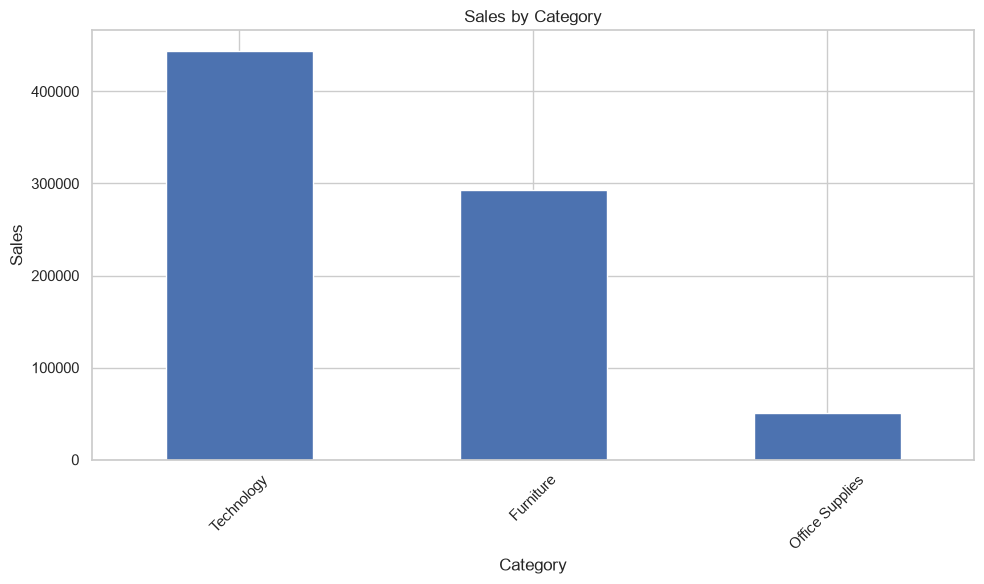

In [10]:
if "Category" in df.columns:

    category_sales = (
        df.groupby("Category", dropna=False)
        .agg(
            Total_Sales=("Sales", "sum"),
            Total_Profit=("Profit", "sum"),
            Total_Quantity=("Quantity", "sum")
        )
        .sort_values("Total_Sales", ascending=False)
    )

    print("CATEGORY ANALYSIS")
    display(category_sales)

    category_sales.to_csv(os.path.join(OUTPUT_DIR, "Category_Analysis.csv"))

    plt.figure(figsize=(10, 6))
    category_sales["Total_Sales"].plot(kind="bar", title="Sales by Category")
    plt.xlabel("Category")
    plt.ylabel("Sales")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "Sales_by_Category.png"))
    plt.show()

SUB-CATEGORY ANALYSIS


,Total_Sales,Total_Profit
Sub_Category,,
Computers,205409.93,30757.30
Living Room,160999.13,22081.07
Phones,93416.71,13789.02
Accessories,84878.81,12683.21
Tablets,63450.00,8732.53
Tables,58095.83,8100.71
Chairs,45765.97,6768.24
Storage,35946.70,5374.49
Machines,33524.29,5410.50


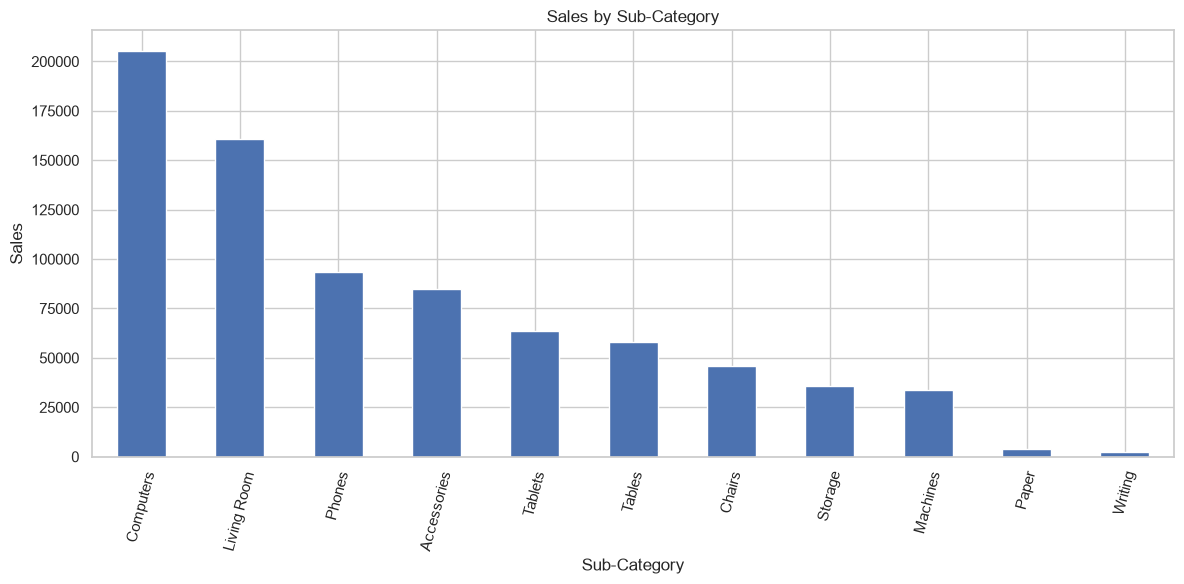

In [11]:
if "Sub_Category" in df.columns:

    subcategory_sales = (
        df.groupby("Sub_Category")
        .agg(
            Total_Sales=("Sales", "sum"),
            Total_Profit=("Profit", "sum")
        )
        .sort_values("Total_Sales", ascending=False)
    )

    print("SUB-CATEGORY ANALYSIS")
    display(subcategory_sales)

    subcategory_sales.to_csv(os.path.join(OUTPUT_DIR, "Sub_Category_Analysis.csv"))

    plt.figure(figsize=(12, 6))
    subcategory_sales["Total_Sales"].plot(kind="bar", title="Sales by Sub-Category")
    plt.xlabel("Sub-Category")
    plt.ylabel("Sales")
    plt.xticks(rotation=75)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "Sales_by_Sub_Category.png"))
    plt.show()

MONTHLY SALES ANALYSIS


,Total_Sales,Total_Profit
Year_Month,,
2024-01,15855.01,2492.91
2024-02,24071.10,3422.63
2024-03,35868.50,3951.03
2024-04,42381.42,6122.87
2024-05,49988.81,7277.59
2024-06,26016.21,3481.52
2024-07,23169.33,3742.57
2024-08,21228.70,2986.67
2024-09,44786.89,5824.13


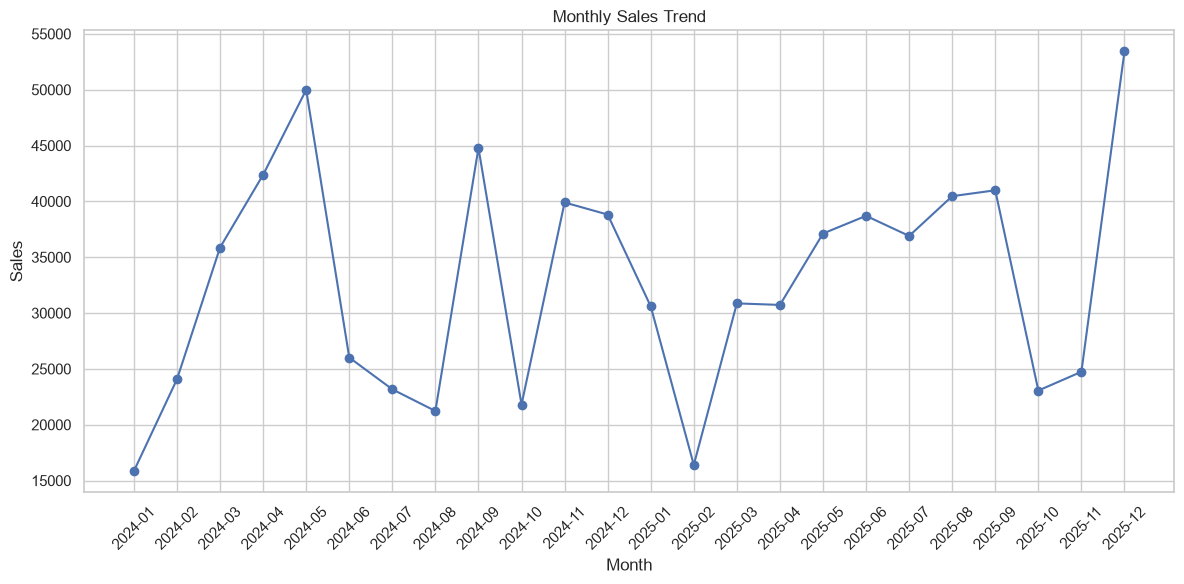

In [12]:
monthly_sales = (
    df.groupby("Year_Month")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .sort_index()
)

print("MONTHLY SALES ANALYSIS")
display(monthly_sales)

monthly_sales.to_csv(os.path.join(OUTPUT_DIR, "Monthly_Sales_Analysis.csv"))

plt.figure(figsize=(12, 6))
plt.plot(monthly_sales.index, monthly_sales["Total_Sales"], marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Monthly_Sales_Trend.png"))
plt.show()

In [13]:
yearly_sales = (
    df.groupby("Year")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .sort_index()
)

print("YEARLY SALES ANALYSIS")
display(yearly_sales)

yearly_sales.to_csv(os.path.join(OUTPUT_DIR, "Yearly_Sales_Analysis.csv"))

YEARLY SALES ANALYSIS


,Total_Sales,Total_Profit,Total_Quantity
Year,,,
2024,383896.01,54644.74,1208
2025,404014.67,59968.99,1252


REGIONAL SALES ANALYSIS


,Total_Sales,Total_Profit,Total_Quantity
Region,,,
West,166305.42,24774.49,554
North,164430.74,22850.21,487
Central,160173.88,23630.42,500
East,150413.66,22055.86,406
South,146586.98,21302.75,513


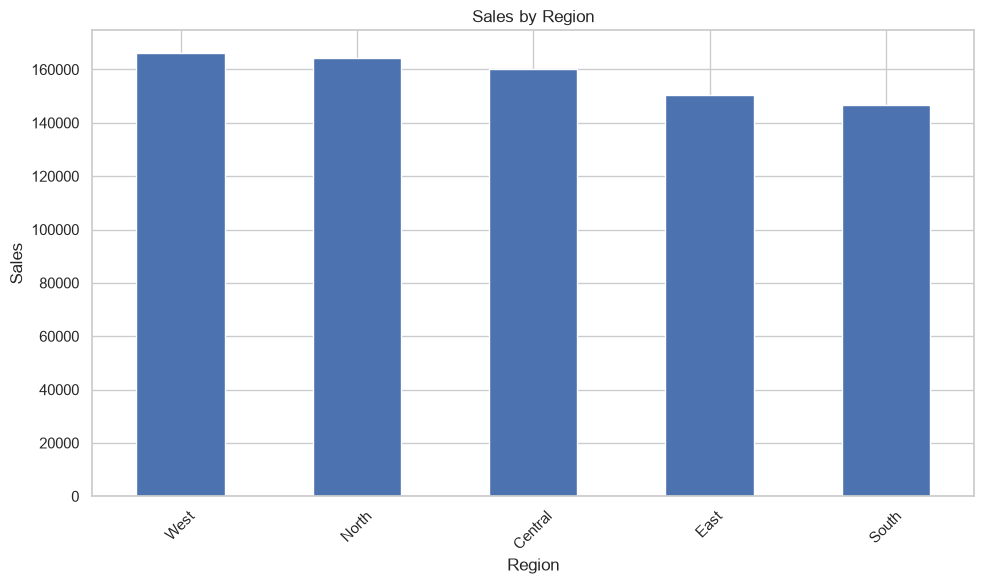

In [14]:
if "Region" in df.columns:

    region_sales = (
        df.groupby("Region")
        .agg(
            Total_Sales=("Sales", "sum"),
            Total_Profit=("Profit", "sum"),
            Total_Quantity=("Quantity", "sum")
        )
        .sort_values("Total_Sales", ascending=False)
    )

    print("REGIONAL SALES ANALYSIS")
    display(region_sales)

    region_sales.to_csv(os.path.join(OUTPUT_DIR, "Regional_Sales_Analysis.csv"))

    plt.figure(figsize=(10, 6))
    region_sales["Total_Sales"].plot(kind="bar", title="Sales by Region")
    plt.xlabel("Region")
    plt.ylabel("Sales")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "Sales_by_Region.png"))
    plt.show()

In [15]:
if "City" in df.columns:

    city_sales = (
        df.groupby("City")
        .agg(
            Total_Sales=("Sales", "sum"),
            Total_Profit=("Profit", "sum")
        )
        .sort_values("Total_Sales", ascending=False)
    )

    print("TOP 10 CITIES")
    display(city_sales.head(10))

    city_sales.to_csv(os.path.join(OUTPUT_DIR, "City_Sales_Analysis.csv"))

TOP 10 CITIES


,Total_Sales,Total_Profit
City,,
Mumbai,63518.74,9858.96
Jaipur,60397.98,8302.13
Chennai,59235.18,7467.07
Bhopal,59165.57,10014.53
Bhubaneswar,57036.48,7927.18
Delhi,52891.37,7431.97
Ahmedabad,52009.67,7335.22
Chandigarh,51141.39,7116.11
Pune,50777.01,7580.31


TOP 10 PRODUCTS BY SALES


,Total_Sales,Total_Profit,Total_Quantity
Product_Name,,,
Laptop,205409.93,30757.30,200
Sofa,160999.13,22081.07,185
Smartphone,93416.71,13789.02,152
Tablet,63450.00,8732.53,153
Monitor,59075.13,9128.55,196
Desk,58095.83,8100.71,139
Office Chair,45765.97,6768.24,193
Printer,33524.29,5410.50,149
Bookshelf,28580.65,4332.44,141


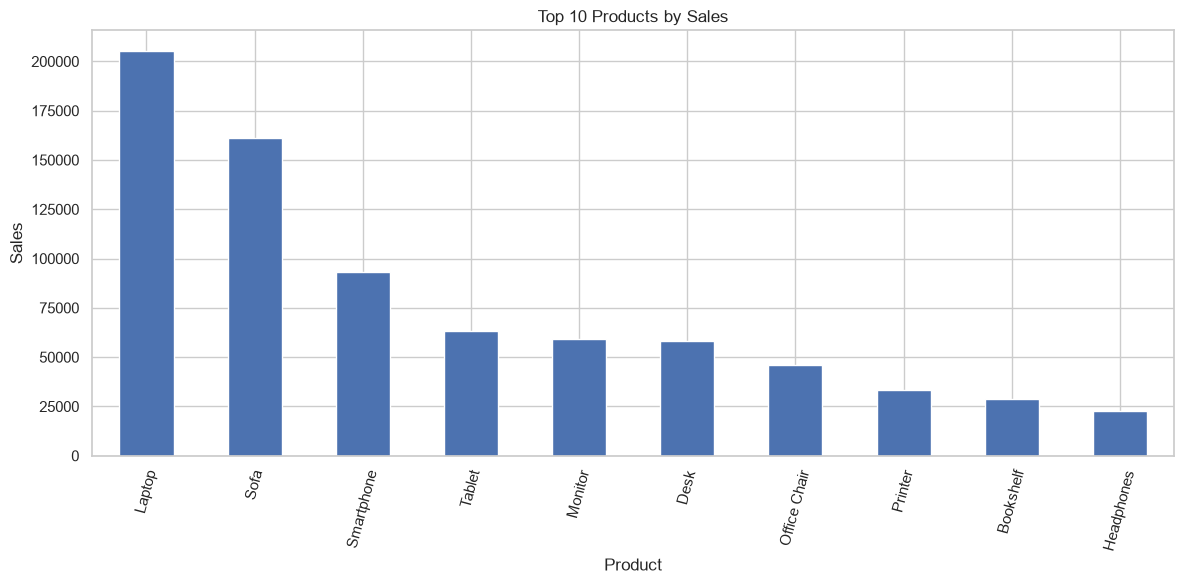

In [16]:
if "Product_Name" in df.columns:

    product_sales = (
        df.groupby("Product_Name")
        .agg(
            Total_Sales=("Sales", "sum"),
            Total_Profit=("Profit", "sum"),
            Total_Quantity=("Quantity", "sum")
        )
        .sort_values("Total_Sales", ascending=False)
    )

    top_10_products = product_sales.head(10)

    print("TOP 10 PRODUCTS BY SALES")
    display(top_10_products)

    top_10_products.to_csv(os.path.join(OUTPUT_DIR, "Top_10_Products.csv"))

    plt.figure(figsize=(12, 6))
    top_10_products["Total_Sales"].plot(kind="bar", title="Top 10 Products by Sales")
    plt.xlabel("Product")
    plt.ylabel("Sales")
    plt.xticks(rotation=75)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "Top_10_Products.png"))
    plt.show()

TOP 10 CUSTOMERS


,Total_Sales,Total_Profit
Customer_Name,,
Customer 033,16053.58,2217.72
Customer 141,14841.54,2521.23
Customer 147,13447.30,2596.79
Customer 051,13034.01,2632.21
Customer 145,12385.60,1785.94
Customer 062,11401.25,1091.07
Customer 031,11195.59,1677.11
Customer 135,10962.21,1540.43
Customer 024,10751.32,1477.32


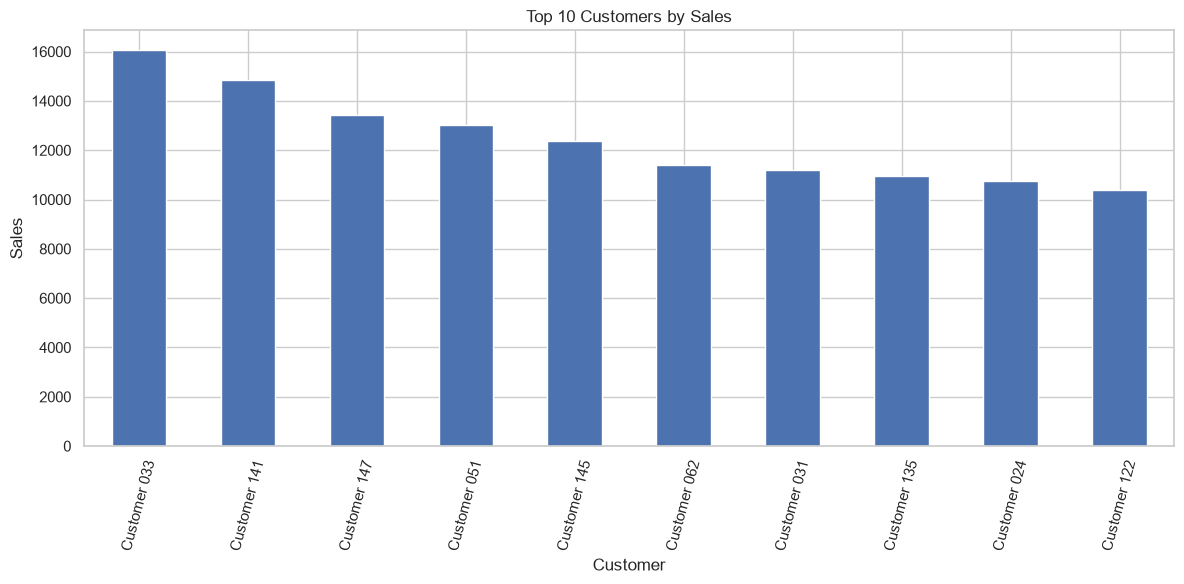

In [17]:
if "Customer_Name" in df.columns:

    customer_sales = (
        df.groupby("Customer_Name")
        .agg(
            Total_Sales=("Sales", "sum"),
            Total_Profit=("Profit", "sum")
        )
        .sort_values("Total_Sales", ascending=False)
    )

    top_10_customers = customer_sales.head(10)

    print("TOP 10 CUSTOMERS")
    display(top_10_customers)

    top_10_customers.to_csv(os.path.join(OUTPUT_DIR, "Top_10_Customers.csv"))

    plt.figure(figsize=(12, 6))
    top_10_customers["Total_Sales"].plot(kind="bar", title="Top 10 Customers by Sales")
    plt.xlabel("Customer")
    plt.ylabel("Sales")
    plt.xticks(rotation=75)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "Top_10_Customers.png"))
    plt.show()

In [18]:
if "Product_Name" in df.columns:

    loss_products = (
        df.groupby("Product_Name")
        .agg(
            Total_Sales=("Sales", "sum"),
            Total_Profit=("Profit", "sum")
        )
        .query("Total_Profit < 0")
        .sort_values("Total_Profit")
    )

    print("LOSS-MAKING PRODUCTS")
    display(loss_products)

    loss_products.to_csv(os.path.join(OUTPUT_DIR, "Loss_Making_Products.csv"))

LOSS-MAKING PRODUCTS


,Total_Sales,Total_Profit
Product_Name,,


In [19]:
if "Discount" in df.columns and "Category" in df.columns:

    discount_analysis = (
        df.groupby("Category")
        .agg(
            Average_Discount=("Discount", "mean"),
            Total_Sales=("Sales", "sum"),
            Total_Profit=("Profit", "sum")
        )
        .sort_values("Average_Discount", ascending=False)
    )

    print("DISCOUNT ANALYSIS")
    display(discount_analysis)

    discount_analysis.to_csv(os.path.join(OUTPUT_DIR, "Discount_Analysis.csv"))

DISCOUNT ANALYSIS


,Average_Discount,Total_Sales,Total_Profit
Category,,,
Technology,0.084964,444032.49,65480.97
Furniture,0.079876,293441.58,41282.46
Office Supplies,0.078603,50436.61,7850.30


In [20]:
if "Category" in df.columns:

    category_profit_margin = (
        df.groupby("Category")
        .agg(
            Total_Sales=("Sales", "sum"),
            Total_Profit=("Profit", "sum")
        )
    )

    category_profit_margin["Profit_Margin_Percentage"] = (
        category_profit_margin["Total_Profit"]
        / category_profit_margin["Total_Sales"].replace(0, float("nan"))
        * 100
    )

    category_profit_margin.sort_values(
        "Profit_Margin_Percentage", ascending=False, inplace=True
    )

    print("PROFIT MARGIN BY CATEGORY")
    display(category_profit_margin)

    category_profit_margin.to_csv(
        os.path.join(OUTPUT_DIR, "Profit_Margin_by_Category.csv")
    )

PROFIT MARGIN BY CATEGORY


,Total_Sales,Total_Profit,Profit_Margin_Percentage
Category,,,
Office Supplies,50436.61,7850.30,15.564686
Technology,444032.49,65480.97,14.746887
Furniture,293441.58,41282.46,14.068374


CORRELATION ANALYSIS


,Sales,Profit,Quantity,Discount
Sales,1.000000,0.872916,0.483363,-0.050330
Profit,0.872916,1.000000,0.408490,-0.122656
Quantity,0.483363,0.408490,1.000000,0.024691
Discount,-0.050330,-0.122656,0.024691,1.000000


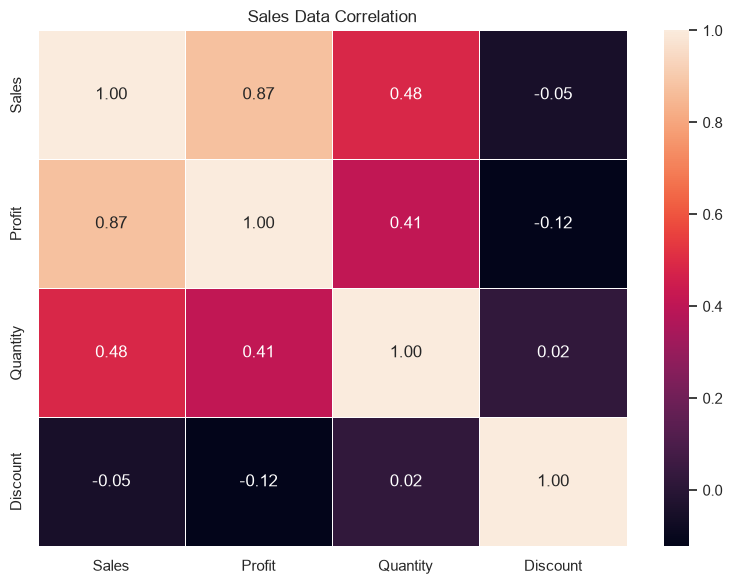

In [21]:
available_numeric_columns = [
    column for column in ["Sales", "Profit", "Quantity", "Discount"]
    if column in df.columns
]

if len(available_numeric_columns) >= 2:

    correlation = df[available_numeric_columns].corr()

    print("CORRELATION ANALYSIS")
    display(correlation)

    correlation.to_csv(os.path.join(OUTPUT_DIR, "Correlation_Analysis.csv"))

    plt.figure(figsize=(8, 6))
    sns.heatmap(correlation, annot=True, fmt=".2f", linewidths=0.5)
    plt.title("Sales Data Correlation")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "Correlation_Heatmap.png"))
    plt.show()

In [22]:
print("=" * 50)
print("           BUSINESS SUMMARY")
print("=" * 50)

print(f"Total Revenue: {total_sales:,.2f}")
print(f"Total Profit: {total_profit:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Total Orders: {total_orders:,}")

if "Category" in df.columns:
    print("Best Selling Category:", df.groupby("Category")["Sales"].sum().idxmax())

if "Region" in df.columns:
    print("Top Performing Region:", df.groupby("Region")["Sales"].sum().idxmax())

if "Product_Name" in df.columns:
    print("Best Selling Product:", df.groupby("Product_Name")["Sales"].sum().idxmax())

if "Customer_Name" in df.columns:
    print("Top Customer:", df.groupby("Customer_Name")["Sales"].sum().idxmax())

           BUSINESS SUMMARY
Total Revenue: 787,910.68
Total Profit: 114,613.73
Profit Margin: 14.55%
Total Orders: 1,200
Best Selling Category: Technology
Top Performing Region: West
Best Selling Product: Laptop
Top Customer: Customer 033


In [23]:
excel_path = os.path.join(OUTPUT_DIR, "Retail_Sales_Complete_Report.xlsx")

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:

    df.to_excel(writer, sheet_name="Cleaned_Data", index=False)
    kpi_data.to_excel(writer, sheet_name="KPI_Summary", index=False)
    monthly_sales.to_excel(writer, sheet_name="Monthly_Sales")
    yearly_sales.to_excel(writer, sheet_name="Yearly_Sales")

    if "Category" in df.columns:
        category_sales.to_excel(writer, sheet_name="Category_Analysis")

    if "Region" in df.columns:
        region_sales.to_excel(writer, sheet_name="Regional_Analysis")

    if "Product_Name" in df.columns:
        product_sales.to_excel(writer, sheet_name="Product_Analysis")

    if "Customer_Name" in df.columns:
        customer_sales.to_excel(writer, sheet_name="Customer_Analysis")

    if "Product_Name" in df.columns:
        loss_products.to_excel(writer, sheet_name="Loss_Products")

    if "Discount" in df.columns and "Category" in df.columns:
        discount_analysis.to_excel(writer, sheet_name="Discount_Analysis")

    if "Category" in df.columns:
        category_profit_margin.to_excel(writer, sheet_name="Profit_Margins")

    if len(available_numeric_columns) >= 2:
        correlation.to_excel(writer, sheet_name="Correlation")

print("Excel Report Created Successfully!")

Excel Report Created Successfully!


In [24]:
print("=" * 50)
print("PROJECT COMPLETED SUCCESSFULLY!")
print("=" * 50)
print("All analysis files saved inside:")
print(os.path.abspath(OUTPUT_DIR))

PROJECT COMPLETED SUCCESSFULLY!
All analysis files saved inside:
C:\Users\HP\Desktop\New folder\Retail_Analysis_Output
